# InsightPulse — Exploratory Data Analysis

Understanding student academic performance through
statistical analysis and data visualization.

## 1. Import Libraries

Import the essential Python libraries required for data manipulation, numerical computation, statistical analysis, and visualization.

In [1]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

print("InsightPulse environment ready!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

InsightPulse environment ready!
NumPy: 2.2.6
Pandas: 2.3.3
Scikit-learn: 1.7.2


## 2. Dataset Overview

Load the student academic performance dataset and inspect its
structure, dimensions, feature names, and data types to understand
the underlying data before performing further analysis.

In [2]:
from pathlib import Path

DATA_PATH = Path("../data/student_data.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


### 2.1 Preview of Dataset

Display the first five records of the dataset to obtain an initial
understanding of the available features, their values, and the
overall structure of student academic performance data.

In [3]:
df.head()

,attendance,assessment_score,study_hours,assignment_completion,previous_score,final_score
0,62.47,42.96,2.83,77.09,70.04,54.36
1,97.04,67.93,2.73,85.77,86.38,65.47
2,83.92,91.11,7.34,47.53,83.21,81.40
3,75.92,81.26,2.75,73.74,40.77,71.53
4,49.36,86.46,2.90,70.02,40.45,65.77


**Initial Observations:**

- Each row represents an individual student.
- The dataset contains five independent features and one target variable.
- All displayed features contain numerical values.
- `final_score` represents the target variable to be predicted.

### 2.2 Dataset Dimensions

Examine the dimensionality of the dataset to determine the total
number of student records, independent features, and target variables.

This provides an overview of the dataset's size and structure
before proceeding with detailed analysis.

In [4]:
print("Dataset Dimensions:", df.shape)
print("Total Student Records:", df.shape[0])
print("Total Features:", df.shape[1] - 1)
print("Total Columns:", df.shape[1])
print("Memory Usage:", round(df.memory_usage(deep=True).sum() / 1024, 2), "KB")

Dataset Dimensions: (1000, 6)
Total Student Records: 1000
Total Features: 5
Total Columns: 6
Memory Usage: 47.0 KB


### 2.3 Dataset Structure and Data Types

Inspect the dataset schema to understand the data types,
non-null counts, and memory consumption of individual columns.

This helps identify potential data type inconsistencies and
provides insights into the dataset's structural integrity.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   attendance             1000 non-null   float64
 1   assessment_score       1000 non-null   float64
 2   study_hours            1000 non-null   float64
 3   assignment_completion  1000 non-null   float64
 4   previous_score         1000 non-null   float64
 5   final_score            1000 non-null   float64
dtypes: float64(6)
memory usage: 47.0 KB


### 2.4 Descriptive Statistical Analysis

Generate descriptive statistics for all numerical features
to understand their central tendency, dispersion, and distribution.

The analysis includes measures such as mean, standard deviation,
minimum, maximum, and quartiles.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
attendance,1000.0,69.41530,17.528108,40.28,54.1550,69.805,84.6625,99.98
assessment_score,1000.0,65.49110,20.453302,30.23,46.8725,66.310,83.2325,99.96
study_hours,1000.0,4.51683,2.034812,1.00,2.8275,4.500,6.3125,7.98
assignment_completion,1000.0,64.32621,20.054215,30.05,46.9325,63.900,81.6275,99.97
previous_score,1000.0,64.58752,20.076778,30.00,47.1475,64.625,81.7975,99.84
final_score,1000.0,65.88740,11.035997,33.62,58.0900,66.090,73.7000,96.39


### 2.5 Feature Classification

Identify the independent variables (predictors) and the
dependent variable (target) to establish the structure
of the supervised machine learning problem.

The objective is to predict students' final academic scores
using their historical academic and behavioral attributes.

In [7]:
# Independent features
X = df.drop(columns=["final_score"])

# Dependent target
y = df["final_score"]

print("Independent Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

print("\nFeature Matrix Shape:", X.shape)
print("Target Vector Shape:", y.shape)

Independent Features:
['attendance', 'assessment_score', 'study_hours', 'assignment_completion', 'previous_score']

Target Variable:
final_score

Feature Matrix Shape: (1000, 5)
Target Vector Shape: (1000,)


## 3. Data Quality Assessment

Evaluate the dataset's completeness, consistency, uniqueness, and validity to identify potential data quality issues before proceeding with exploratory data analysis and machine learning.

The objective is to ensure that the dataset contains reliable and appropriately structured observations by examining missing values, duplicate records, data types, and invalid entries.

### 3.1 Missing Value Analysis

Identify missing or null values in the dataset and calculate their percentage across individual features to assess data completeness.

The objective is to ensure that all academic and behavioral attributes contain valid observations before proceeding with statistical analysis and machine learning model development.

In [8]:
# Calculate missing values in each column
missing_values = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (missing_values / len(df)) * 100

# Create a structured summary
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage.round(2)
})

# Display the summary
missing_summary

,Missing Values,Missing Percentage
attendance,0,0.0
assessment_score,0,0.0
study_hours,0,0.0
assignment_completion,0,0.0
previous_score,0,0.0
final_score,0,0.0


### 3.2 Duplicate Record Detection

Identify duplicate records in the dataset to ensure that identical observations do not introduce unnecessary redundancy or bias into the analysis.

The objective is to evaluate the uniqueness of student records by detecting completely duplicated rows and calculating their percentage relative to the total number of observations.

In [9]:
# Count duplicate records
duplicate_count = df.duplicated().sum()

# Calculate duplicate percentage
duplicate_percentage = (duplicate_count / len(df)) * 100

# Display duplicate record statistics
print("Duplicate Records:", duplicate_count)
print("Duplicate Percentage:", round(duplicate_percentage, 2), "%")

Duplicate Records: 0
Duplicate Percentage: 0.0 %


### 3.3 Data Type Validation

Examine the data types of each feature to ensure that the dataset is represented in appropriate formats for statistical analysis and machine learning.

The objective is to verify that numerical attributes are stored using compatible data types and identify any inconsistencies that may require data type conversion before model development.

In [10]:
# Examine data types and unique values
dtype_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Unique Values": df.nunique()
})

# Display the summary
dtype_summary

,Data Type,Unique Values
attendance,float64,926
assessment_score,float64,938
study_hours,float64,540
assignment_completion,float64,924
previous_score,float64,928
final_score,float64,885


### 3.4 Invalid Value Detection

Identify values that fall outside the expected ranges of the dataset's features to ensure consistency and validity of the recorded observations.

The objective is to verify that academic attributes such as attendance, assessment scores, assignment completion, and final scores remain within their valid percentage ranges, while study hours remain within a reasonable daily limit.

In [11]:
# Define valid ranges for each feature
valid_ranges = {
    "attendance": (0, 100),
    "assessment_score": (0, 100),
    "study_hours": (0, 24),
    "assignment_completion": (0, 100),
    "previous_score": (0, 100),
    "final_score": (0, 100)
}

# Check for values outside the defined ranges
for column, (lower, upper) in valid_ranges.items():
    invalid_count = ((df[column] < lower) | (df[column] > upper)).sum()
    print(f"{column}: {invalid_count} invalid records")

attendance: 0 invalid records
assessment_score: 0 invalid records
study_hours: 0 invalid records
assignment_completion: 0 invalid records
previous_score: 0 invalid records
final_score: 0 invalid records


### 3.5 Overall Data Quality Summary

Consolidate the findings from the previous data quality assessments to obtain an overall view of the dataset's completeness, uniqueness, and validity.

The objective is to summarize the number of records, features, missing values, duplicate records, and invalid values to determine whether the dataset is suitable for further exploratory data analysis and machine learning preparation.

In [12]:
# Calculate overall data quality metrics
total_missing = df.isnull().sum().sum()
total_duplicates = df.duplicated().sum()

total_invalid = sum(
    ((df[column] < lower) | (df[column] > upper)).sum()
    for column, (lower, upper) in valid_ranges.items()
)

# Create overall data quality summary
quality_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Features",
        "Missing Values",
        "Duplicate Records",
        "Invalid Values"
    ],
    "Count": [
        len(df),
        df.shape[1] - 1,
        total_missing,
        total_duplicates,
        total_invalid
    ]
})

# Display the summary
quality_summary

,Metric,Count
0,Total Records,1000
1,Total Features,5
2,Missing Values,0
3,Duplicate Records,0
4,Invalid Values,0


## 4. Exploratory Data Analysis (EDA)

Explore the dataset using statistical methods and visualizations to understand feature distributions, identify patterns, and examine relationships among variables.

The objective is to gain meaningful insights into student academic and behavioral attributes before proceeding to feature engineering and machine learning model development.

### 4.1 Univariate Analysis

Examine individual features independently using statistical summaries and visualizations to understand their distributions, central tendencies, and variability.

The objective is to understand the characteristics of each academic and behavioral attribute, identify potential patterns, and observe the distribution of student data before analyzing relationships between multiple variables.

#### 4.1.1 Distribution of Individual Features

Analyze the distribution of individual numerical features using histograms and Kernel Density Estimation (KDE) curves to understand how observations are spread across different value ranges.

The objective is to examine the frequency, concentration, variability, and potential skewness of student academic and behavioral attributes, providing insights into the underlying distribution of each feature.

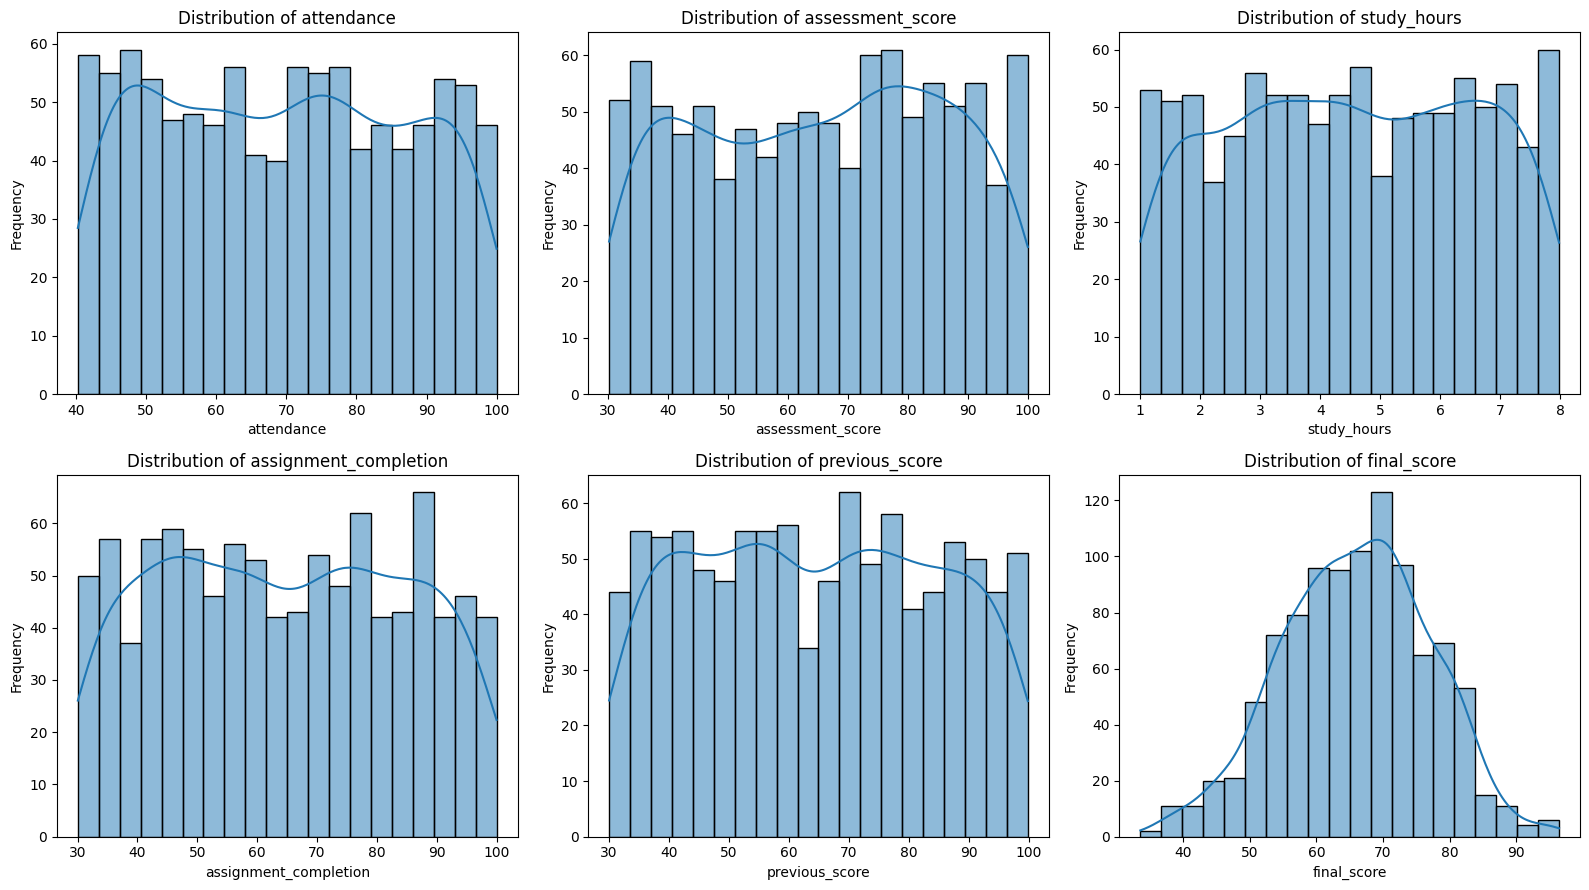

In [13]:
# Select numerical features for distribution analysis
features = df.columns

# Create subplots for individual feature distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

# Plot histogram with KDE for each feature
for i, column in enumerate(features):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=20,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

# Adjust layout
plt.tight_layout()
plt.show()

#### 4.1.2 Box Plot Analysis

Examine the distribution and spread of individual numerical features using box plots to understand their central tendency, variability, and potential outliers.

The objective is to analyze the median, quartiles, interquartile range (IQR), and extreme observations of each feature. This helps identify unusual values that may require further investigation before machine learning model development.

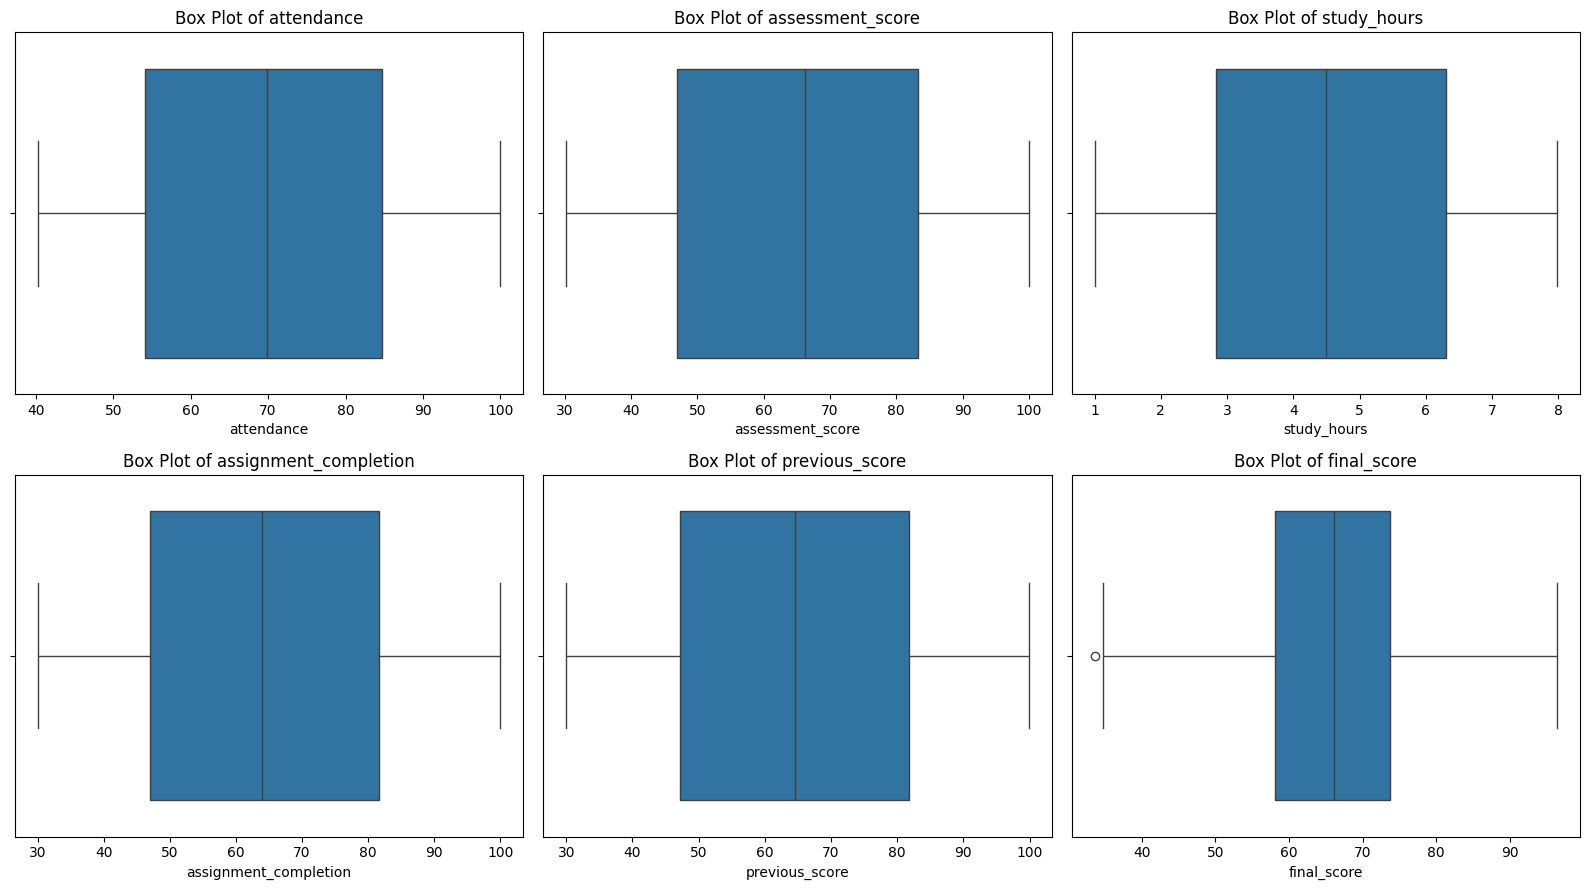

In [14]:
# Select numerical features for box plot analysis
features = df.columns

# Create subplots for individual feature box plots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

# Generate box plots for each feature
for i, column in enumerate(features):
    sns.boxplot(
        data=df,
        x=column,
        ax=axes[i]
    )

    axes[i].set_title(f"Box Plot of {column}")
    axes[i].set_xlabel(column)

# Adjust layout
plt.tight_layout()
plt.show()

#### 4.1.3 Statistical Summary of Features

Calculate descriptive statistical measures for individual numerical features to understand their central tendency, dispersion, and overall distribution.

The objective is to examine measures such as mean, median, standard deviation, minimum, maximum, and quartiles to complement the visual analysis and gain a quantitative understanding of the dataset.

In [15]:
# Calculate descriptive statistics for all features
statistical_summary = df.describe().T

# Add median as an additional statistical measure
statistical_summary["median"] = df.median()

# Display the statistical summary
statistical_summary.round(2)

,count,mean,std,min,25%,50%,75%,max,median
attendance,1000.0,69.42,17.53,40.28,54.16,69.81,84.66,99.98,69.81
assessment_score,1000.0,65.49,20.45,30.23,46.87,66.31,83.23,99.96,66.31
study_hours,1000.0,4.52,2.03,1.00,2.83,4.50,6.31,7.98,4.50
assignment_completion,1000.0,64.33,20.05,30.05,46.93,63.90,81.63,99.97,63.90
previous_score,1000.0,64.59,20.08,30.00,47.15,64.62,81.80,99.84,64.62
final_score,1000.0,65.89,11.04,33.62,58.09,66.09,73.70,96.39,66.09


### 4.2 Distribution Analysis

Analyze the statistical shape of numerical feature distributions using skewness and kurtosis to understand their symmetry and tail characteristics.

The objective is to identify deviations from normality, examine the presence of asymmetry, and understand the concentration of observations across different features. These insights will help guide subsequent feature transformation and model selection decisions.

#### 4.2.1 Skewness and Kurtosis Analysis

Examine the asymmetry and tail characteristics of numerical feature distributions using skewness and kurtosis statistical measures.

The objective is to determine how closely the feature distributions resemble a normal distribution, identify potential asymmetry, and understand the concentration and spread of observations across individual features.

In [16]:
# Calculate skewness and kurtosis for all numerical features
distribution_analysis = pd.DataFrame({
    "Skewness": df.skew(),
    "Kurtosis": df.kurt()
})

# Display the results
distribution_analysis.round(3)

,Skewness,Kurtosis
attendance,0.039,-1.229
assessment_score,-0.059,-1.217
study_hours,-0.022,-1.194
assignment_completion,0.030,-1.200
previous_score,0.032,-1.194
final_score,-0.115,-0.238


#### 4.2.2 Kernel Density Distribution Comparison

Compare the distribution shapes of numerical features using Kernel Density Estimation (KDE) curves to understand their density patterns and overall characteristics.

The objective is to examine the similarities and differences in distribution shapes across academic and behavioral attributes. Standardizing the features allows distributions with different measurement scales to be compared on a common scale.

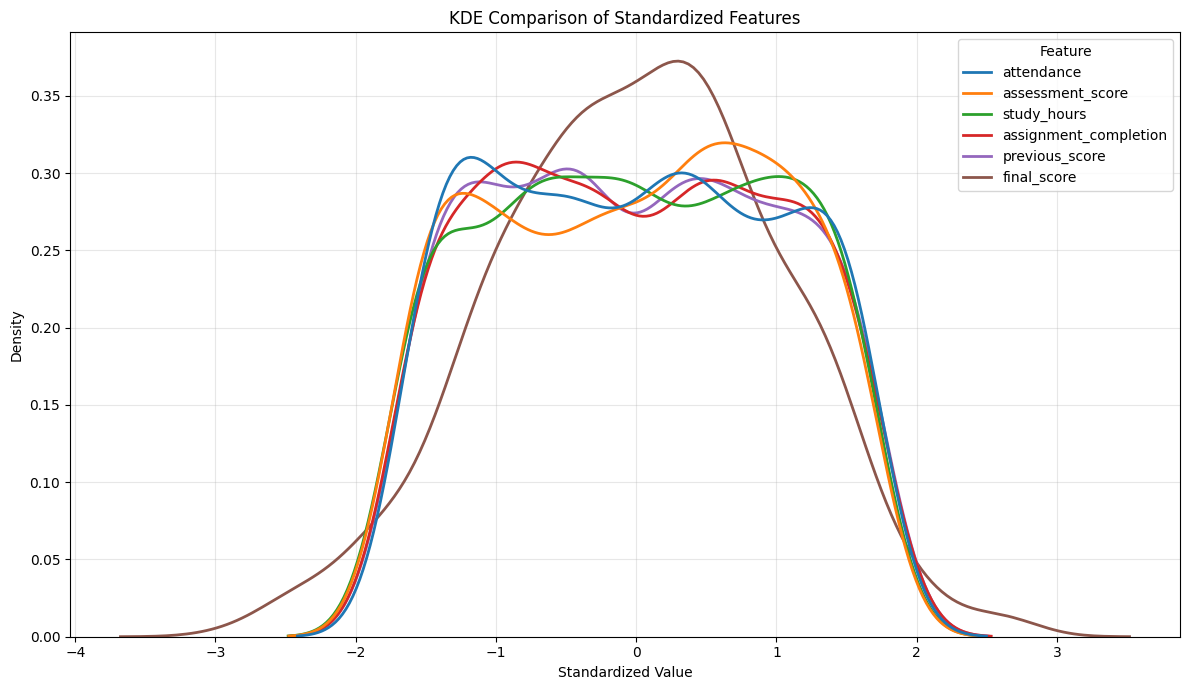

In [17]:
# Standardize numerical features for distribution comparison
standardized_df = (df - df.mean()) / df.std()

# Convert the dataset into long format
melted_df = standardized_df.melt(
    var_name="Feature",
    value_name="Standardized Value"
)

# Plot KDE curves for all features
plt.figure(figsize=(12, 7))

sns.kdeplot(
    data=melted_df,
    x="Standardized Value",
    hue="Feature",
    fill=False,
    common_norm=False,
    linewidth=2
)

# Add plot details
plt.title("KDE Comparison of Standardized Features")
plt.xlabel("Standardized Value")
plt.ylabel("Density")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4.3 Bivariate Analysis

Investigate the relationships between pairs of numerical variables to identify associations, trends, and dependencies within the dataset.

The objective is to understand how individual academic and behavioral attributes interact with one another and influence students' final academic performance. This analysis helps identify potentially important predictors and provides insights for subsequent feature selection and machine learning model development.

#### 4.3.1 Feature vs Target Relationship

Examine the relationship between individual predictor variables and the target variable using scatter plots to identify potential associations, trends, and patterns.

The objective is to understand how academic and behavioral attributes such as attendance, assessment scores, study hours, assignment completion, and previous scores relate to students' final academic performance.

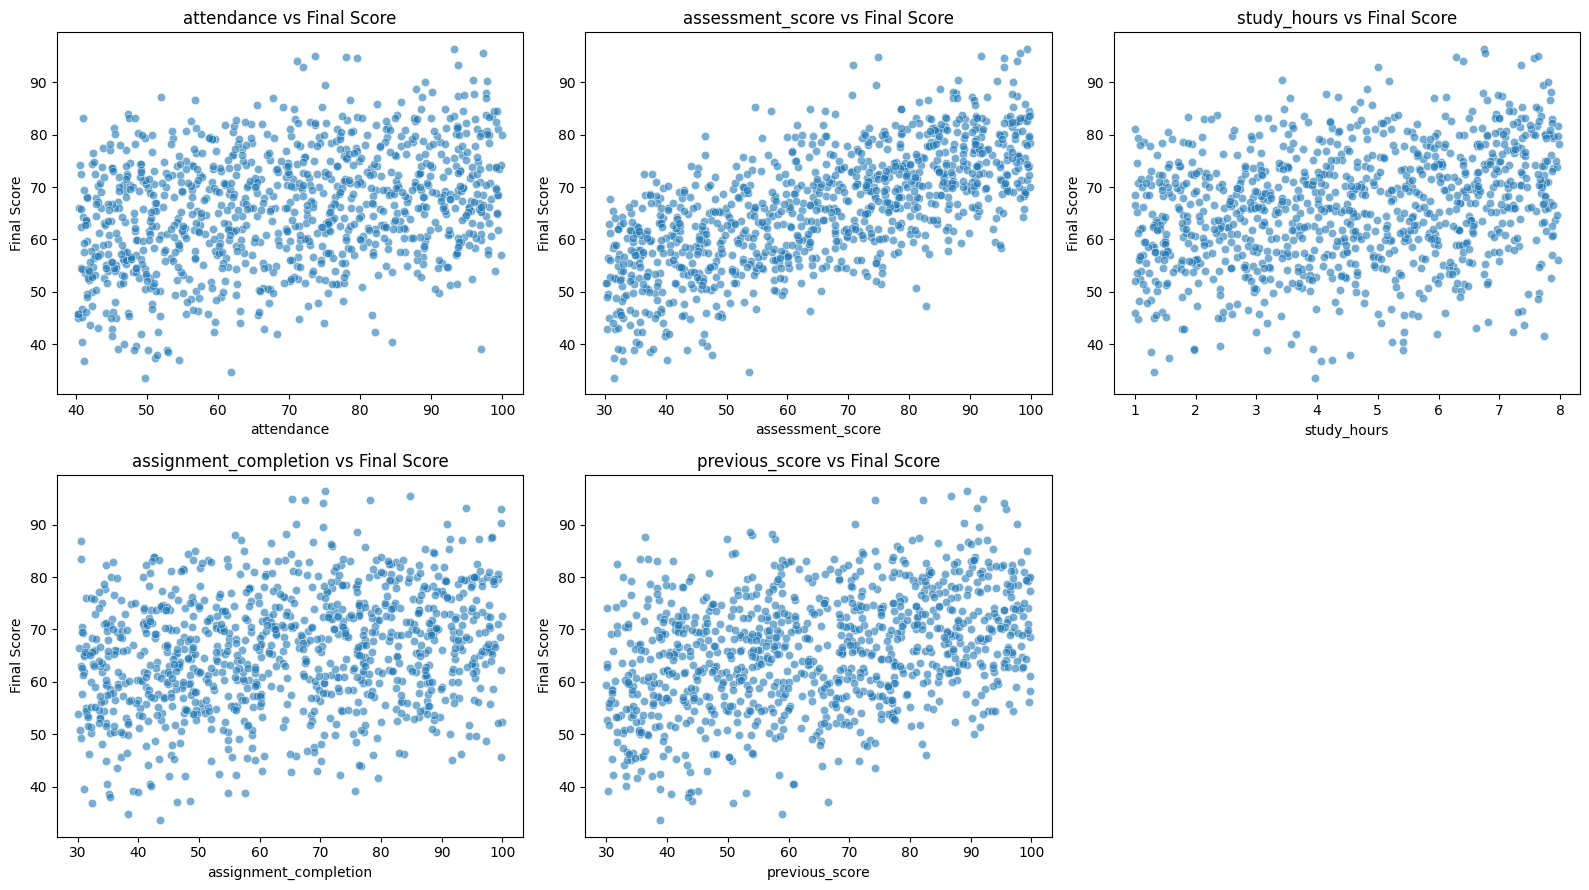

In [18]:
# Select independent features
features = X.columns

# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

# Generate scatter plots
for i, column in enumerate(features):
    sns.scatterplot(
        data=df,
        x=column,
        y="final_score",
        alpha=0.6,
        ax=axes[i]
    )

    axes[i].set_title(f"{column} vs Final Score")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Final Score")

# Hide unused subplot
for j in range(len(features), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

#### 4.3.2 Pairwise Feature Relationships

Examine pairwise relationships among numerical features using a pair plot to identify patterns, associations, and potential dependencies between variables.

The objective is to understand how independent features interact with one another and how their distributions and relationships vary across the dataset. This analysis also helps identify potential multicollinearity among predictor variables.

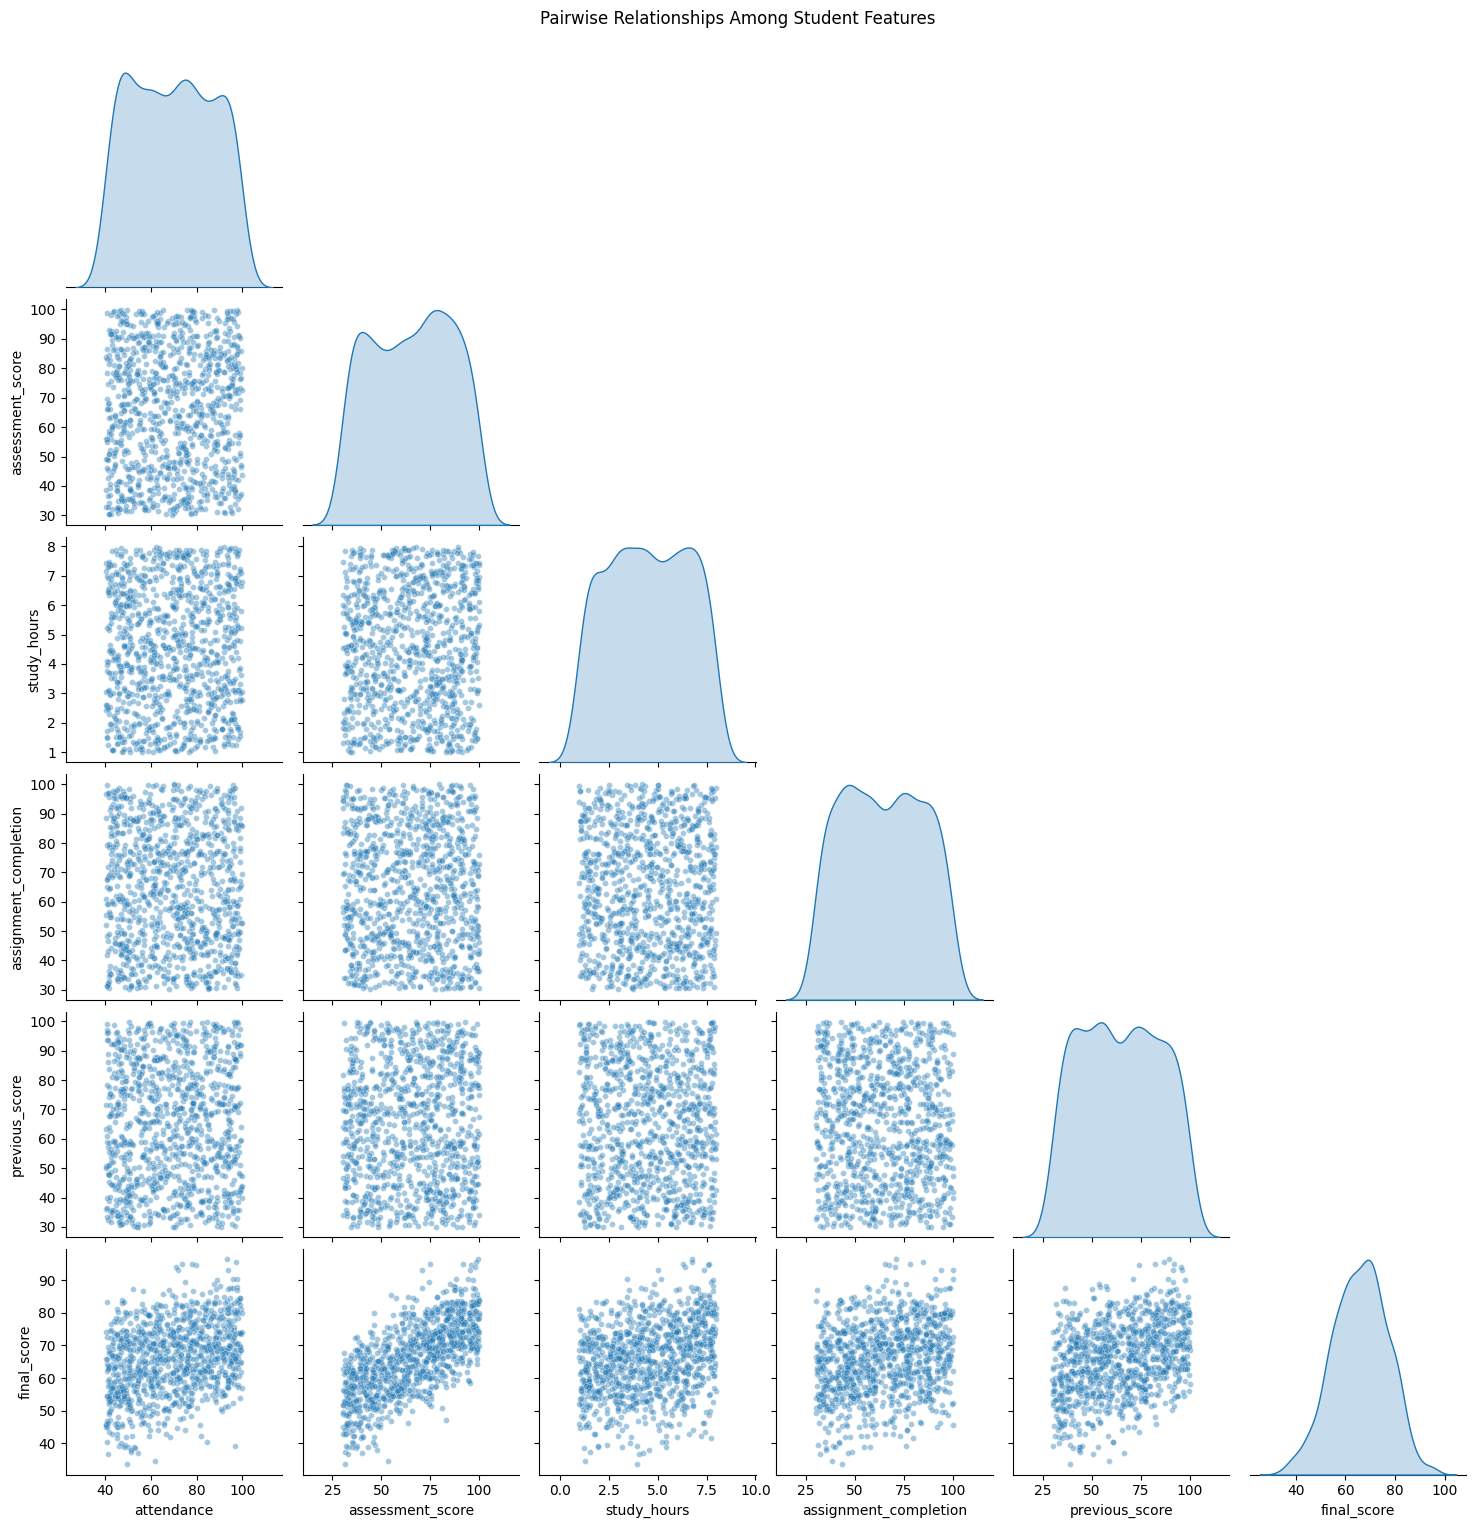

In [19]:
# Generate pairwise relationships among all numerical features
pair_plot = sns.pairplot(
    df,
    diag_kind="kde",
    corner=True,
    plot_kws={"alpha": 0.4, "s": 18}
)

# Add an overall title
pair_plot.fig.suptitle(
    "Pairwise Relationships Among Student Features",
    y=1.02
)

plt.show()

#### 4.3.3 Correlation Analysis

Quantify the linear relationships between numerical features using Pearson correlation coefficients and visualize the results through a correlation heatmap.

The objective is to measure the strength and direction of associations among independent variables and the target variable, identify potentially important predictors, and investigate possible multicollinearity within the feature set.

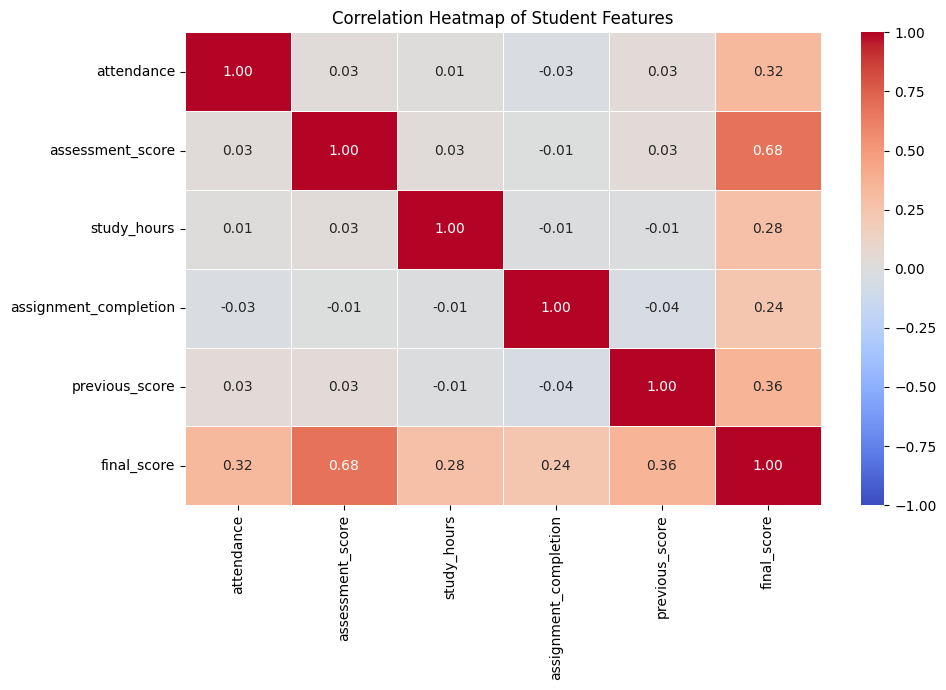

In [20]:
# Calculate the Pearson correlation matrix
correlation_matrix = df.corr(method="pearson")

# Create a correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

# Add plot details
plt.title("Correlation Heatmap of Student Features")
plt.tight_layout()
plt.show()

#### 4.3.4 Multicollinearity Assessment

Evaluate the degree of multicollinearity among independent features using the Variance Inflation Factor (VIF), a statistical measure that quantifies how strongly a predictor can be explained by the remaining predictors.

The objective is to identify potential redundancy among independent variables and assess whether highly correlated features could affect the stability and interpretability of regression model coefficients.

In [21]:
# Calculate the correlation matrix of independent features
feature_correlation = X.corr()

# Calculate the inverse of the correlation matrix
inverse_correlation = np.linalg.inv(feature_correlation)

# Extract diagonal values as VIF scores
vif_values = np.diag(inverse_correlation)

# Create a VIF summary
vif_summary = pd.DataFrame({
    "Feature": X.columns,
    "VIF": vif_values
})

# Display VIF scores
vif_summary.round(3)

,Feature,VIF
0,attendance,1.003
1,assessment_score,1.003
2,study_hours,1.001
3,assignment_completion,1.003
4,previous_score,1.004


### 4.4 Feature-Target Relationship Analysis

Investigate the individual relationships between independent features and the target variable using statistical techniques to understand their predictive associations.

The objective is to identify potentially influential predictors of students' final academic performance, quantify their relationships with the target variable, and establish a foundation for subsequent feature selection and machine learning model development.

#### 4.4.1 Feature Correlation Ranking

Rank independent features according to their Pearson correlation coefficients with the target variable to identify the strength and direction of their linear relationships with students' final academic performance.

The objective is to prioritize potentially informative predictors based on their absolute correlation values and establish a quantitative basis for subsequent feature selection and model development.

In [22]:
# Calculate correlation of each feature with the target variable
target_correlations = df.corr()["final_score"].drop("final_score")

# Create a feature correlation summary
feature_target_summary = pd.DataFrame({
    "Correlation": target_correlations,
    "Absolute Correlation": target_correlations.abs()
})

# Rank features by absolute correlation
feature_target_summary = feature_target_summary.sort_values(
    by="Absolute Correlation",
    ascending=False
)

# Display ranked features
feature_target_summary.round(3)

,Correlation,Absolute Correlation
assessment_score,0.680,0.680
previous_score,0.356,0.356
attendance,0.321,0.321
study_hours,0.277,0.277
assignment_completion,0.238,0.238


#### 4.4.2 Visual Representation of Feature Correlations

Visualize the ranked correlation coefficients using a horizontal bar chart to compare the strength and direction of relationships between independent features and the target variable.

The objective is to provide a clear visual comparison of predictor associations and identify features with stronger linear relationships with students' final academic performance.

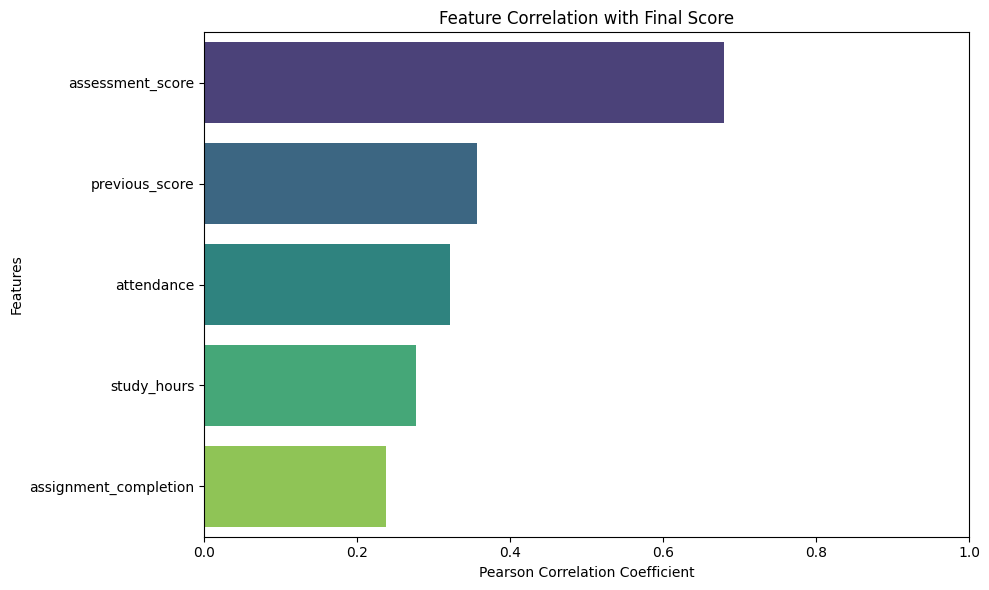

In [23]:
# Create a horizontal bar chart of feature correlations
plt.figure(figsize=(10, 6))

sns.barplot(
    x="Correlation",
    y=feature_target_summary.index,
    data=feature_target_summary,
    hue=feature_target_summary.index,
    palette="viridis",
    legend=False
)

# Add plot details
plt.title("Feature Correlation with Final Score")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Features")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()

#### 4.4.3 Feature Interaction Analysis

Investigate potential interaction patterns between selected independent features to understand whether combinations of academic and behavioral attributes are associated with variations in students' final academic performance.

The objective is to explore whether the relationship between one predictor and the target variable may vary across different levels of another predictor, providing insights into potential interaction effects for subsequent feature engineering and model development.


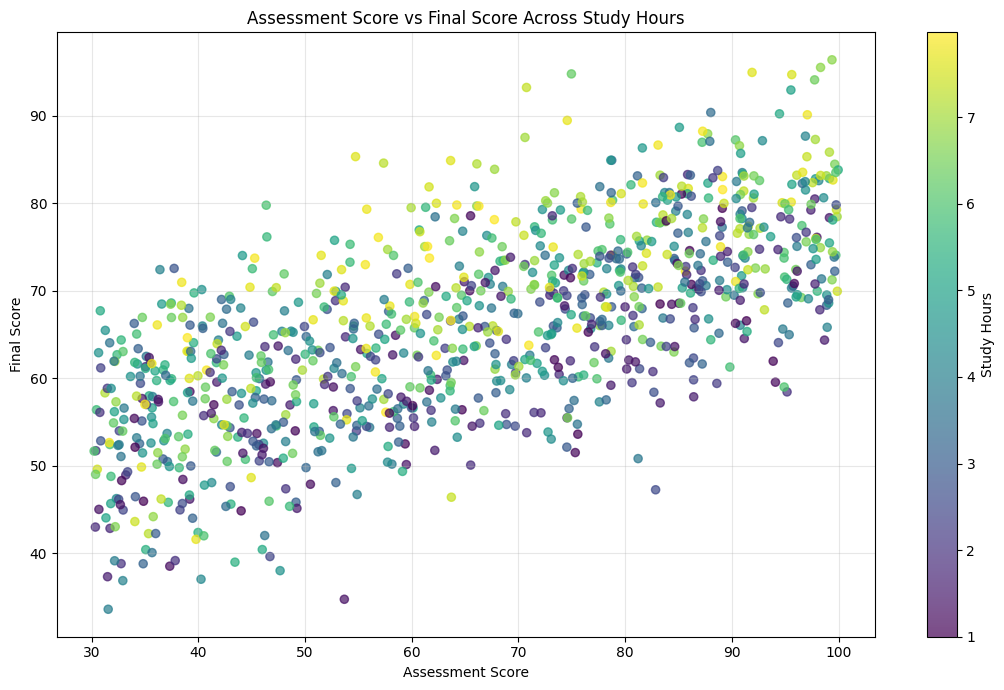

In [24]:
# Create a scatter plot to examine feature interactions
plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    data=df,
    x="assessment_score",
    y="final_score",
    c=df["study_hours"],
    cmap="viridis",
    alpha=0.7,
    s=35
)

# Add color bar to represent study hours
cbar = plt.colorbar(scatter)
cbar.set_label("Study Hours")

# Add plot details
plt.title("Assessment Score vs Final Score Across Study Hours")
plt.xlabel("Assessment Score")
plt.ylabel("Final Score")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4.5 EDA Summary and Key Findings

Consolidate the findings obtained from univariate, distributional, bivariate, correlation, and multicollinearity analyses to develop an overall understanding of the dataset.

The objective is to summarize important statistical patterns, identify potentially influential predictors, evaluate relationships among features, and establish data-driven insights that will guide subsequent feature engineering and machine learning model development.

#### 4.5.1 EDA Findings Summary

Summarize the key findings obtained throughout the exploratory data analysis using a structured overview of statistical patterns, feature relationships, and data quality observations.

The objective is to consolidate important insights, identify potentially valuable predictors, and establish a clear understanding of the dataset before proceeding to feature engineering and machine learning model development.

In [25]:
# Identify the strongest and weakest correlated predictors
strongest_feature = target_correlations.abs().idxmax()
weakest_feature = target_correlations.abs().idxmin()

# Identify the feature with the highest VIF
highest_vif_feature = vif_summary.loc[
    vif_summary["VIF"].idxmax(), "Feature"
]

# Create a structured EDA findings summary
eda_summary = pd.DataFrame({
    "Analysis": [
        "Dataset Quality",
        "Missing Values",
        "Duplicate Records",
        "Invalid Values",
        "Distribution Characteristics",
        "Strongest Target Association",
        "Weakest Target Association",
        "Multicollinearity",
        "Highest VIF Feature"
    ],
    "Key Findings": [
        f"{len(df)} records and {X.shape[1]} independent features",
        str(total_missing),
        str(total_duplicates),
        str(total_invalid),
        "Predictors are approximately symmetric and relatively flat",
        f"{strongest_feature}: {target_correlations[strongest_feature]:.3f}",
        f"{weakest_feature}: {target_correlations[weakest_feature]:.3f}",
        "Negligible multicollinearity among predictors",
        f"{highest_vif_feature}: {vif_summary['VIF'].max():.3f}"
    ]
})

# Display the consolidated findings
eda_summary

,Analysis,Key Findings
0,Dataset Quality,1000 records and 5 independent features
1,Missing Values,0
2,Duplicate Records,0
3,Invalid Values,0
4,Distribution Characteristics,Predictors are approximately symmetric and rel...
5,Strongest Target Association,assessment_score: 0.680
6,Weakest Target Association,assignment_completion: 0.238
7,Multicollinearity,Negligible multicollinearity among predictors
8,Highest VIF Feature,previous_score: 1.004


## 5. Feature Engineering and Data Preparation

Prepare the dataset for machine learning by validating predictor variables, separating training and testing data, applying appropriate feature transformations, and developing a structured preprocessing workflow.

The objective is to create a reliable, reproducible, and leakage-free data preparation pipeline that ensures consistent input representations for model training and evaluation.

### 5.1 Feature Selection and Validation

Identify and validate the independent variables and dependent target variable required for machine learning model development.

The objective is to confirm that the selected features are relevant, correctly structured, and suitable for predicting students' final academic performance. This step also ensures that the target variable is excluded from the predictor set to prevent data leakage.

In [28]:
# Define independent features and dependent target
X = df.drop(columns=["final_score"])
y = df["final_score"]

# Validate feature and target separation
assert "final_score" not in X.columns
assert X.shape[0] == y.shape[0]

# Create feature validation summary
feature_validation = pd.DataFrame({
    "Data Type": X.dtypes,
    "Missing Values": X.isnull().sum(),
    "Unique Values": X.nunique()
})

# Display selected features
print("Independent Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

print("\nFeature Matrix Shape:", X.shape)
print("Target Vector Shape:", y.shape)

print("\nFeature Validation Summary:")
feature_validation

Independent Features:
['attendance', 'assessment_score', 'study_hours', 'assignment_completion', 'previous_score']

Target Variable:
final_score

Feature Matrix Shape: (1000, 5)
Target Vector Shape: (1000,)

Feature Validation Summary:


,Data Type,Missing Values,Unique Values
attendance,float64,0,926
assessment_score,float64,0,938
study_hours,float64,0,540
assignment_completion,float64,0,924
previous_score,float64,0,928


### 5.2 Train-Test Split

Divide the dataset into separate training and testing subsets using the train_test_split utility from Scikit-learn.

The objective is to allocate 80% of the observations for model training and reserve the remaining 20% for independent evaluation. This separation helps assess the model's ability to generalize to unseen student records and reduces the risk of evaluating performance on data used during training.

In [29]:
# Import train-test split utility
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset dimensions
print("Training Feature Set:", X_train.shape)
print("Testing Feature Set:", X_test.shape)

print("Training Target Set:", y_train.shape)
print("Testing Target Set:", y_test.shape)

# Calculate split percentages
print("\nTraining Data:", round(len(X_train) / len(df) * 100, 2), "%")
print("Testing Data:", round(len(X_test) / len(df) * 100, 2), "%")

Training Feature Set: (800, 5)
Testing Feature Set: (200, 5)
Training Target Set: (800,)
Testing Target Set: (200,)

Training Data: 80.0 %
Testing Data: 20.0 %


### 5.3 Feature Scaling and Standardization

Transform numerical features into a common scale using standardization to prevent differences in measurement ranges from disproportionately influencing machine learning algorithms.

The objective is to ensure that each predictor contributes on a comparable scale by centering its values around zero and scaling them according to their standard deviation. This is particularly important for distance-based and gradient-based algorithms.

In [30]:
# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the training scaler
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back into DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=X_test.index
)

# Display scaled training features
X_train_scaled.head()

,attendance,assessment_score,study_hours,assignment_completion,previous_score
29,-1.533891,1.077638,0.507808,0.508463,-0.445442
535,1.536299,-1.345440,1.129939,-1.243215,0.350003
695,0.394234,-1.529534,0.038741,-1.590264,1.370150
557,-1.594270,-0.354471,-0.716703,0.005067,0.668081
836,1.433770,-1.323898,1.678006,1.555087,-0.386020


#### 5.3.1 Standardization Validation

Validate the effectiveness of feature standardization by examining the mean and standard deviation of the transformed training features.

The objective is to confirm that each standardized feature has approximately zero mean and unit standard deviation, ensuring that the scaling transformation has been applied correctly and consistently across all independent variables.

In [31]:
# Calculate mean and standard deviation of scaled training features
scaling_validation = pd.DataFrame({
    "Mean": X_train_scaled.mean(),
    "Standard Deviation": X_train_scaled.std(ddof=0)
})

# Display validation results
scaling_validation.round(4)

,Mean,Standard Deviation
attendance,-0.0,1.0
assessment_score,0.0,1.0
study_hours,-0.0,1.0
assignment_completion,0.0,1.0
previous_score,0.0,1.0


### 5.4 Feature Engineering

Develop additional meaningful predictor variables from existing academic and behavioral attributes to potentially improve the representation of student performance patterns.

The objective is to capture useful information that may not be fully represented by individual raw features and investigate whether engineered variables can improve the predictive capability of subsequent machine learning models.

#### 5.4.1 Academic Performance Indicators

Construct additional academic and behavioral indicators using existing independent features to capture student performance trends and engagement patterns.

The objective is to derive meaningful information from previous academic scores, assessment performance, attendance, and assignment completion without introducing the target variable into the feature engineering process.

In [32]:
# Create copies of training and testing features
X_train_engineered = X_train.copy()
X_test_engineered = X_test.copy()

# Feature 1: Academic score progress
X_train_engineered["score_progress"] = (
    X_train_engineered["assessment_score"]
    - X_train_engineered["previous_score"]
)

X_test_engineered["score_progress"] = (
    X_test_engineered["assessment_score"]
    - X_test_engineered["previous_score"]
)

# Feature 2: Student engagement index
X_train_engineered["engagement_index"] = (
    X_train_engineered["attendance"]
    + X_train_engineered["assignment_completion"]
) / 2

X_test_engineered["engagement_index"] = (
    X_test_engineered["attendance"]
    + X_test_engineered["assignment_completion"]
) / 2

# Display engineered training features
X_train_engineered.head()

,attendance,assessment_score,study_hours,assignment_completion,previous_score,score_progress,engagement_index
29,42.79,88.02,5.58,74.26,55.23,32.79,58.525
535,96.69,38.53,6.84,39.08,71.16,-32.63,67.885
695,76.64,34.77,4.63,32.11,91.59,-56.82,54.375
557,41.73,58.77,3.10,64.15,77.53,-18.76,52.940
836,94.89,38.97,7.95,95.28,56.42,-17.45,95.085


#### 5.4.2 Engineered Feature Validation

Validate the newly constructed academic and behavioral features by examining their statistical properties, data types, and completeness.

The objective is to ensure that the engineered variables contain valid numerical values, have no missing observations, and are correctly integrated into the training and testing feature sets before subsequent preprocessing and model development.

In [33]:
# Validate engineered training features
engineered_validation = pd.DataFrame({
    "Data Type": X_train_engineered.dtypes,
    "Missing Values": X_train_engineered.isnull().sum(),
    "Unique Values": X_train_engineered.nunique()
})

# Display validation summary
engineered_validation

,Data Type,Missing Values,Unique Values
attendance,float64,0,753
assessment_score,float64,0,752
study_hours,float64,0,484
assignment_completion,float64,0,758
previous_score,float64,0,750
score_progress,float64,0,789
engagement_index,float64,0,771


In [34]:
# Validate engineered testing features
test_validation = pd.DataFrame({
    "Data Type": X_test_engineered.dtypes,
    "Missing Values": X_test_engineered.isnull().sum(),
    "Unique Values": X_test_engineered.nunique()
})

# Verify training and testing feature consistency
assert X_train_engineered.columns.equals(X_test_engineered.columns)

# Display testing validation summary
test_validation

,Data Type,Missing Values,Unique Values
attendance,float64,0,198
assessment_score,float64,0,199
study_hours,float64,0,176
assignment_completion,float64,0,195
previous_score,float64,0,198
score_progress,float64,0,199
engagement_index,float64,0,199


### 5.5 Data Leakage Prevention

Establish appropriate data handling practices to prevent information from the testing dataset or target variable from influencing model training and feature transformation.

The objective is to maintain a reliable evaluation process by ensuring that statistical transformations are learned exclusively from training data, engineered features use only independent variables, and the testing dataset remains isolated until final model evaluation.

#### 5.5.1 Data Leakage Prevention Validation

Verify the data preparation workflow to ensure that target information is excluded from independent features and that training and testing datasets remain properly separated.

The objective is to validate the feature-target separation, consistent feature engineering, and training-only fitting of preprocessing transformations to minimize the risk of data leakage during subsequent model development.

In [36]:
# Verify target variable is excluded from engineered features
assert "final_score" not in X_train_engineered.columns
assert "final_score" not in X_test_engineered.columns

# Verify training and testing feature consistency
assert X_train_engineered.columns.equals(
    X_test_engineered.columns
)

# Verify training and testing records remain separate
assert set(X_train_engineered.index).isdisjoint(
    set(X_test_engineered.index)
)

# Verify scaler was fitted using training data
assert scaler.n_samples_seen_ == len(X_train)

print("Target leakage check: Passed")
print("Feature consistency check: Passed")
print("Train-test separation check: Passed")
print("Training-only scaler fitting: Passed")

Target leakage check: Passed
Feature consistency check: Passed
Train-test separation check: Passed
Training-only scaler fitting: Passed


### 5.6 Scikit-learn Preprocessing Pipeline

Develop a reusable preprocessing workflow using Scikit-learn's Pipeline and transformation utilities to standardize engineered features consistently before machine learning model training.

The objective is to integrate feature scaling into a structured and reproducible workflow, ensuring that preprocessing transformations are fitted exclusively on training data and applied consistently to unseen observations. This approach also supports leakage-free cross-validation and hyperparameter optimization.

#### 5.6.1 Building the Preprocessing Pipeline

Construct a Scikit-learn Pipeline that combines feature standardization into a single reusable preprocessing workflow.

The objective is to automate the scaling process, maintain consistency between training and testing data, and prepare a clean interface for integrating machine learning algorithms in subsequent stages.

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocessing_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

# Fit the pipeline using training data only
X_train_processed = preprocessing_pipeline.fit_transform(
    X_train_engineered
)

# Transform testing data using the fitted pipeline
X_test_processed = preprocessing_pipeline.transform(
    X_test_engineered
)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Pipeline steps:", preprocessing_pipeline.named_steps)

Training data shape: (800, 7)
Testing data shape: (200, 7)
Pipeline steps: {'scaler': StandardScaler()}


#### 5.6.2 Preprocessing Pipeline Validation

Evaluate the output of the preprocessing pipeline to verify that feature standardization has been performed correctly and consistently across the training and testing datasets.

The objective is to confirm that the training features have approximately zero mean and unit standard deviation, while the testing features are transformed using the scaling parameters learned exclusively from the training dataset.

In [39]:
# Convert processed arrays back into DataFrames
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=X_train_engineered.columns,
    index=X_train_engineered.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=X_test_engineered.columns,
    index=X_test_engineered.index
)

# Validate training feature standardization
scaling_summary = pd.DataFrame({
    "Training Mean": X_train_processed_df.mean(),
    "Training Std": X_train_processed_df.std(ddof=0),
    "Testing Mean": X_test_processed_df.mean(),
    "Testing Std": X_test_processed_df.std(ddof=0)
})

scaling_summary.round(4)

,Training Mean,Training Std,Testing Mean,Testing Std
attendance,-0.0,1.0,-0.0865,0.9865
assessment_score,0.0,1.0,-0.1270,0.9981
study_hours,-0.0,1.0,-0.0857,1.0179
assignment_completion,0.0,1.0,0.0692,0.9882
previous_score,0.0,1.0,0.1091,1.0053
score_progress,-0.0,1.0,-0.1700,0.9985
engagement_index,0.0,1.0,-0.0048,0.9276


### 5.7 Final Dataset Preparation

Consolidate the prepared training and testing datasets into their final forms for subsequent machine learning development.

The objective is to verify dataset dimensions, feature consistency, target alignment, and data integrity before introducing regression algorithms. This final validation ensures that the prepared data can be passed reliably into model training and evaluation workflows.

#### 5.7.1 Final Dataset Integrity Checks

Perform a final verification of the prepared training and testing datasets before model development.

The objective is to ensure that both datasets contain the expected number of records and features, that feature columns are consistent, that target values are correctly aligned with their corresponding observations, and that no missing or infinite values remain after preprocessing.

In [40]:
# Verify dataset dimensions
print("Training features shape:", X_train_processed_df.shape)
print("Testing features shape:", X_test_processed_df.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

# Verify feature consistency
assert X_train_processed_df.columns.equals(
    X_test_processed_df.columns
)

# Verify feature-target alignment
assert X_train_processed_df.index.equals(y_train.index)
assert X_test_processed_df.index.equals(y_test.index)

# Verify no missing or infinite values
assert X_train_processed_df.notna().all().all()
assert X_test_processed_df.notna().all().all()

assert np.isfinite(X_train_processed_df.to_numpy()).all()
assert np.isfinite(X_test_processed_df.to_numpy()).all()

assert y_train.notna().all()
assert y_test.notna().all()

assert np.isfinite(y_train.to_numpy()).all()
assert np.isfinite(y_test.to_numpy()).all()

# Verify train-test separation
assert set(X_train_processed_df.index).isdisjoint(
    set(X_test_processed_df.index)
)

print("\nAll final dataset integrity checks passed!")

Training features shape: (800, 7)
Testing features shape: (200, 7)
Training target shape: (800,)
Testing target shape: (200,)

All final dataset integrity checks passed!


## 6. Model Development and Training

Develop and train multiple supervised machine learning regression algorithms to predict students' final academic scores using the prepared dataset.

The objective is to establish baseline performance, compare different regression approaches, identify patterns learned by each algorithm, and determine which model provides the most reliable predictions. Model selection will use cross-validation on the training dataset, while the held-out testing dataset will remain untouched until final evaluation.

### 6.1 Establishing a Baseline Model

Establish a baseline regression model using Scikit-learn's DummyRegressor to create a reference point for evaluating the performance of more sophisticated machine learning algorithms.

The objective is to determine how well a simple prediction strategy performs without learning relationships between input features and the target variable. This baseline will help assess whether subsequent machine learning models provide meaningful predictive improvements.

#### 6.1.1 Building the Baseline Model

Implement a baseline regression model using Scikit-learn's DummyRegressor with the mean prediction strategy.

The model will predict the average final score calculated from the training dataset for every observation, without considering individual student features. This provides a reference performance level against which more advanced regression algorithms can be compared.

In [41]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Initialize the baseline model
baseline_model = DummyRegressor(strategy="mean")

# Train the model using training data
baseline_model.fit(X_train_processed_df, y_train)

# Generate predictions on training data
baseline_train_predictions = baseline_model.predict(
    X_train_processed_df
)

# Generate predictions on testing data
baseline_test_predictions = baseline_model.predict(
    X_test_processed_df
)

# Evaluate baseline performance on testing data
baseline_mae = mean_absolute_error(
    y_test, baseline_test_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_test_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_test_predictions
)

# Display evaluation results
baseline_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Baseline Score": [
        baseline_mae,
        baseline_rmse,
        baseline_r2
    ]
})

baseline_results.round(4)

,Metric,Baseline Score
0,MAE,8.7490
1,RMSE,10.6741
2,R²,-0.0010


### 6.2 Linear Regression

Implement a Linear Regression model to establish the first feature-based predictive approach for estimating students' final academic scores.

The objective is to learn the linear relationships between academic indicators and final performance, evaluate the model's predictive capabilities, and determine whether incorporating student-specific features improves upon the established baseline.

#### 6.2.1 Building the Linear Regression Model

Implement a Linear Regression algorithm using Scikit-learn to learn the relationship between the engineered academic features and students' final scores.

The model will estimate the contribution of each input feature to the predicted outcome by learning optimal coefficients and an intercept from the training dataset. This establishes a foundational predictive model for subsequent performance comparison.

In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Initialize the Linear Regression pipeline
linear_regression_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Train using the training dataset
linear_regression_pipeline.fit(
    X_train_engineered,
    y_train
)

# Extract the trained Linear Regression model
linear_model = linear_regression_pipeline.named_steps["model"]

# Display model coefficients
coefficient_summary = pd.DataFrame({
    "Feature": X_train_engineered.columns,
    "Coefficient": linear_model.coef_
})

coefficient_summary["Absolute Coefficient"] = (
    coefficient_summary["Coefficient"].abs()
)

coefficient_summary = coefficient_summary.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

print("Intercept:", round(linear_model.intercept_, 4))
coefficient_summary.round(4)

Intercept: 65.955


,Feature,Coefficient,Absolute Coefficient
1,assessment_score,6.3130,6.3130
4,previous_score,4.6489,4.6489
2,study_hours,2.8817,2.8817
6,engagement_index,2.2345,2.2345
0,attendance,2.0928,2.0928
5,score_progress,1.2748,1.2748
3,assignment_completion,1.1305,1.1305


#### 6.2.2 Cross-Validation

Evaluate the Linear Regression model using K-Fold Cross-Validation to assess its consistency and generalization capability across multiple training and validation splits.

The objective is to obtain a more reliable estimate of model performance by training and validating the algorithm across different subsets of the training dataset, reducing dependence on a single data split.

In [43]:
from sklearn.model_selection import KFold, cross_validate

# Define 5-fold cross-validation strategy
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring_metrics = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Perform cross-validation on training data
cv_results = cross_validate(
    linear_regression_pipeline,
    X_train_engineered,
    y_train,
    cv=kfold,
    scoring=scoring_metrics,
    return_train_score=True
)

# Convert negative error scores into positive values
cv_summary = pd.DataFrame({
    "Fold": range(1, 6),
    "MAE": -cv_results["test_MAE"],
    "RMSE": -cv_results["test_RMSE"],
    "R2": cv_results["test_R2"]
})

# Calculate mean and standard deviation
cv_summary.loc["Mean"] = [
    "Average",
    cv_summary["MAE"].mean(),
    cv_summary["RMSE"].mean(),
    cv_summary["R2"].mean()
]

cv_summary.loc["Std Dev"] = [
    "Variation",
    cv_summary["MAE"].std(),
    cv_summary["RMSE"].std(),
    cv_summary["R2"].std()
]

cv_summary.round(4)

,Fold,MAE,RMSE,R2
0,1,4.0311,4.9462,0.8095
1,2,4.2111,5.1830,0.8104
2,3,3.8729,4.8562,0.7979
3,4,3.7820,4.7588,0.8058
4,5,3.9755,4.9829,0.7762
Mean,Average,3.9745,4.9454,0.8000
Std Dev,Variation,0.1460,0.1419,0.0127


#### 6.2.3 Cross-Validation Performance Analysis

Visualize and analyze the evaluation metrics obtained across the five cross-validation folds to understand the stability and consistency of the Linear Regression model.

The objective is to identify variations in predictive performance across different validation subsets and assess whether the model generalizes consistently across the training dataset.